# 01 - Data Exploration
**Goal:** load the raw airline passengers data, parse dates and diagnose problems (duplicates, gaps, missing values).

In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import cleaning as cl
RAW = "../data/raw/airline_passengers_dirty.csv"
plt.rcParams["figure.figsize"] = (10, 4)

## Load the raw file
The dates are strings and the rows are shuffled, so we inspect first.

In [2]:
raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(144, 2)


,Month,Passengers
0,1949-12,118.0
1,1959-05,420.0
2,1952-02,180.0
3,1951-09,184.0
4,1955-01,242.0


## Parse dates and set a datetime index

In [3]:
raw['Month'] = pd.to_datetime(raw['Month'])
df = raw.set_index('Month').sort_index()
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Passengers  136 non-null    float64
dtypes: float64(1)
memory usage: 2.2 KB


## Check duplicates, missing values and missing timestamps

In [4]:
print('Duplicate timestamps:', df.index.duplicated().sum())
print('Missing values     :', df['Passengers'].isna().sum())
full = pd.date_range(df.index.min(), df.index.max(), freq='MS')
print('Missing timestamps :', len(full.difference(df.index)))
print(full.difference(df.index).strftime('%Y-%m').tolist())

Duplicate timestamps: 2
Missing values     : 8
Missing timestamps : 2
['1953-06', '1954-12']


## Plot the raw series
Outliers and gaps are visible as spikes and breaks in the line.

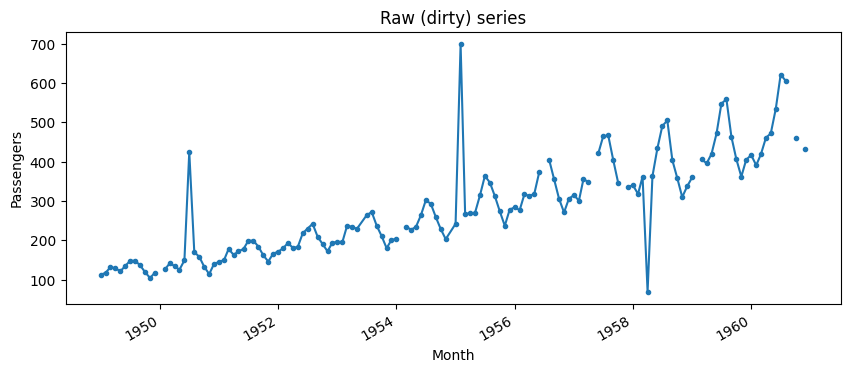

In [5]:
df = df[~df.index.duplicated()]
df['Passengers'].plot(marker='.', title='Raw (dirty) series');
plt.ylabel('Passengers'); plt.show()

**Findings:** the data has duplicates, missing timestamps, missing values and a few extreme spikes. We fix each one in the next notebooks.